# State-Space Models and the Kalman Filter

A state-space model has a latent state $\alpha_t$ and noisy observations $y_t$. In the local-level model $\mu_t=\mu_{t-1}+\eta_t$, $y_t=\mu_t+\varepsilon_t$ and the Kalman filter predicts, compares with the observation (innovation $v_t$, variance $F_t$), and updates with gain $K_t=P_{t|t-1}/F_t$.

This notebook verifies the note's worked update ($a=10$, $P=1.25$, $y=12$, $R=1$), reproduces its gain table, runs a hand-coded filter and compares it with statsmodels, and illustrates smoothing, missing data, and standardized innovations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from statsmodels.tsa.statespace.structural import UnobservedComponents
from statsmodels.graphics.tsaplots import plot_acf

rng = np.random.default_rng(5)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

def update(a, P, y, R):
    v = y - a
    F = P + R
    K = P / F
    return a + K * v, (1 - K) * P, v, F, K

a, P, v, F, K = update(10, 1.25, 12, 1)
print(f"v={v}  F={F}  K={K:.4f}  a_t|t={a:.4f}  P_t|t={P:.4f}")

print("\nP_t|t-1    R    gain   updated level")
for P0, R in [(1.25, 1), (1.25, 4), (4, 1)]:
    a1, _, _, _, k1 = update(10, P0, 12, R)
    print(f"{P0:7.2f} {R:4d} {k1:7.3f} {a1:10.3f}")

v=2  F=2.25  K=0.5556  a_t|t=11.1111  P_t|t=0.5556

P_t|t-1    R    gain   updated level
   1.25    1   0.556     11.111
   1.25    4   0.238     10.476
   4.00    1   0.800     11.600


This reproduces $v_t=2$, $F_t=2.25$, $K_t=0.5556$, $a_{t|t}=11.1111$, $P_{t|t}=0.5556$, and the table rows $(0.556,\,11.111)$, $(0.238,\,10.476)$, $(0.800,\,11.600)$. Noisier measurement lowers the gain; larger prior uncertainty raises it.

## Local level: hand-coded Kalman filter

Simulate $\mu_t$ with $Q=0.5$ and $R=2$, then filter with the scalar recursions and a diffuse-like start. We also record the log-likelihood contributions $\ell_t=-\tfrac12[\log2\pi+\log F_t+v_t^2/F_t]$.

steady-state gain K_T      : 0.3904
steady-state P_pred theory : 1.2808  filter: 1.2808
steady-state gain theory   : 0.3904
log-likelihood             : -393.79
RMSE: observation vs mu    : 1.365
RMSE: filtered   vs mu     : 0.815


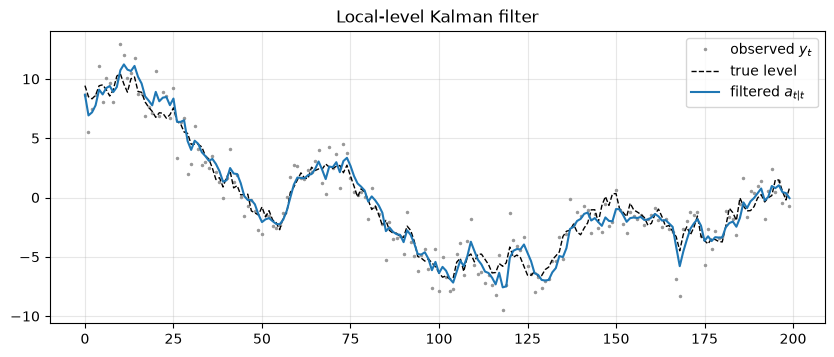

In [2]:
T, Q, R = 200, 0.5, 2.0
mu = np.cumsum(rng.normal(0, np.sqrt(Q), T)) + 10
y = mu + rng.normal(0, np.sqrt(R), T)

def kalman_ll(y, Q, R, a0=None, P0=1e6):
    a_prev = y[0] if a0 is None else a0
    P_prev = P0
    n = len(y)
    out = {k: np.full(n, np.nan) for k in ("a", "P", "v", "F", "K", "a_pred", "P_pred", "ll")}
    for t in range(n):
        a_p, P_p = a_prev, P_prev + Q                 # prediction
        if np.isnan(y[t]):                            # missing: skip update
            a_t, P_t = a_p, P_p
            v = F = K = ll = np.nan
        else:
            a_t, P_t, v, F, K = update(a_p, P_p, y[t], R)
            ll = -0.5 * (np.log(2 * np.pi) + np.log(F) + v**2 / F)
        for k, val in zip(out, (a_t, P_t, v, F, K, a_p, P_p, ll)):
            out[k][t] = val
        a_prev, P_prev = a_t, P_t
    return out

f = kalman_ll(y, Q, R)
print("steady-state gain K_T      :", f["K"][-1].round(4))
# steady-state P_pred solves P = P(R)/(P+R) + Q
Pss = (Q + np.sqrt(Q**2 + 4 * Q * R)) / 2
print("steady-state P_pred theory :", Pss.round(4), " filter:", f["P_pred"][-1].round(4))
print("steady-state gain theory   :", (Pss / (Pss + R)).round(4))
print("log-likelihood             :", np.nansum(f["ll"][1:]).round(2))
print("RMSE: observation vs mu    :", np.sqrt(np.mean((y - mu) ** 2)).round(3))
print("RMSE: filtered   vs mu     :", np.sqrt(np.mean((f["a"] - mu) ** 2)).round(3))

plt.figure(figsize=(10, 3.8))
plt.plot(y, ".", ms=3, color="0.6", label="observed $y_t$")
plt.plot(mu, "k--", lw=1, label="true level")
plt.plot(f["a"], lw=1.5, label="filtered $a_{t|t}$")
plt.legend(); plt.title("Local-level Kalman filter"); plt.show()

The filtered level is much closer to the true latent level than the raw observations. The gain converges to its steady-state value implied by $P=\dfrac{PR}{P+R}+Q$, which sets the exponential-smoothing weight the filter applies to each new innovation.

## Compare with statsmodels, smoothing, and missing data

`UnobservedComponents(level='llevel')` estimates $Q$ and $R$ by maximum likelihood using the same Kalman recursions. We then compare filtered and smoothed states and create a gap to see uncertainty grow without updates.

estimated var(irregular) R : 1.525 (true 2.0)
estimated var(level)     Q : 0.727 (true 0.5)
max |hand - statsmodels| filtered level (t>=5): 0.0
RMSE filtered vs mu : 0.865
RMSE smoothed vs mu : 0.724
P_t|t at t=99, 109, 119, 120: [ 0.781  5.781 10.781  1.699]


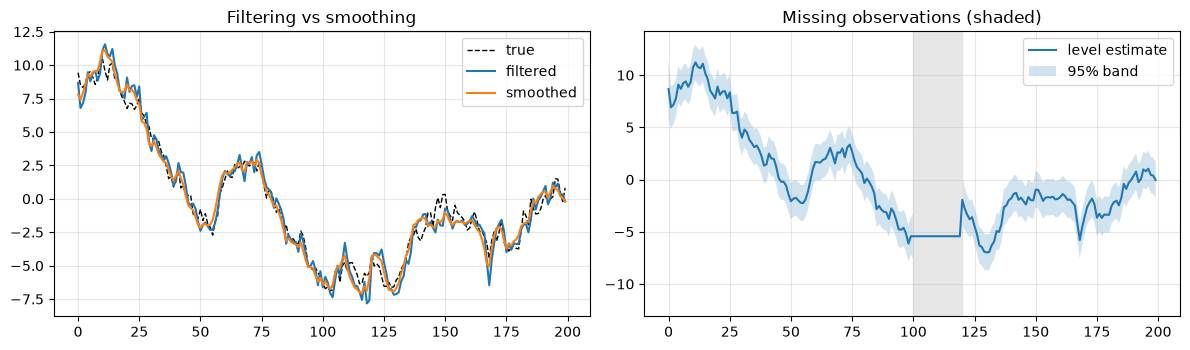

In [3]:
mod = UnobservedComponents(y, level="llevel")
res = mod.fit(disp=False)
print("estimated var(irregular) R :", res.params[0].round(3), "(true 2.0)")
print("estimated var(level)     Q :", res.params[1].round(3), "(true 0.5)")

# hand filter with the estimated parameters vs statsmodels filtered state
hf = kalman_ll(y, res.params[1], res.params[0], a0=0.0, P0=1e7)
print("max |hand - statsmodels| filtered level (t>=5):",
      np.abs(hf["a"][5:] - res.filtered_state[0][5:]).max().round(4))

filt, smooth = res.filtered_state[0], res.smoothed_state[0]
print("RMSE filtered vs mu :", np.sqrt(np.mean((filt - mu) ** 2)).round(3))
print("RMSE smoothed vs mu :", np.sqrt(np.mean((smooth - mu) ** 2)).round(3))

# Missing block
ym = y.copy(); ym[100:120] = np.nan
fm = kalman_ll(ym, Q, R)
print("P_t|t at t=99, 109, 119, 120:", fm["P"][[99, 109, 119, 120]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(mu, "k--", lw=1, label="true"); ax[0].plot(filt, label="filtered"); ax[0].plot(smooth, label="smoothed")
ax[0].legend(); ax[0].set_title("Filtering vs smoothing")
ax[1].plot(fm["a"], label="level estimate"); ax[1].fill_between(np.arange(T), fm["a"] - 1.96*np.sqrt(fm["P"]),
    fm["a"] + 1.96*np.sqrt(fm["P"]), alpha=0.2, label="95% band")
ax[1].axvspan(100, 120, color="0.9"); ax[1].legend(); ax[1].set_title("Missing observations (shaded)")
plt.tight_layout(); plt.show()

Our recursions match statsmodels once the same parameters are used. The smoothed path has lower error than the filtered one because it uses future data, so it should not be used to judge a real-time procedure. During the missing block the estimate is only propagated (the state is a random walk) and the variance grows by $Q$ each step, then drops again once observations return.

## Standardized innovations

Under an adequate model $\tilde v_t=v_t/\sqrt{F_t}$ should look like white noise with unit variance. We check this for the correct model and for a misspecified one whose level variance is far too small.

correct Q=0.5  mean=-0.070  var=0.926  Ljung-Box(10) p=0.259  loglik=-393.8
wrong Q=0.005  mean=-0.734  var=3.793  Ljung-Box(10) p=3.26e-130  loglik=-675.1


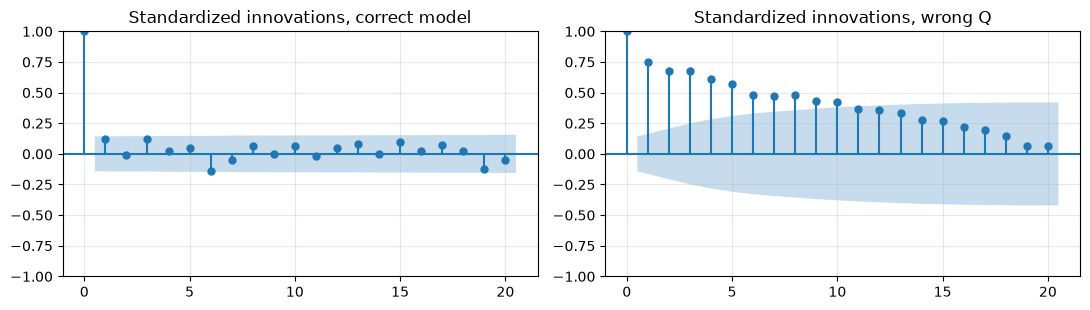

In [4]:
from statsmodels.stats.diagnostic import acorr_ljungbox

good = kalman_ll(y, Q, R)
bad = kalman_ll(y, 0.005, R)               # level assumed almost constant
for name, o in [("correct Q=0.5", good), ("wrong Q=0.005", bad)]:
    z = (o["v"] / np.sqrt(o["F"]))[10:]
    lb = acorr_ljungbox(z, lags=[10]).iloc[0]["lb_pvalue"]
    print(f"{name:<14} mean={z.mean():6.3f}  var={z.var():5.3f}  Ljung-Box(10) p={lb:.3g}  loglik={np.nansum(o['ll'][1:]):.1f}")

zg = (good["v"] / np.sqrt(good["F"]))[10:]
zb = (bad["v"] / np.sqrt(bad["F"]))[10:]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
plot_acf(zg, lags=20, ax=ax[0], title="Standardized innovations, correct model")
plot_acf(zb, lags=20, ax=ax[1], title="Standardized innovations, wrong Q")
plt.tight_layout(); plt.show()

The correctly specified filter yields unit-variance, essentially uncorrelated standardized innovations and the higher log-likelihood; the misspecified filter leaves strong serial correlation (the level drifts but the filter does not follow it) and a clearly lower likelihood. Innovation diagnostics are therefore the natural model check for state-space models.